# Option Payoff Diagrams

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots profit or loss at expiry against the underlying price for an option strategy, with the premium paid or received included. Small multiples put several strategies side by side, so their risk profiles (capped, unlimited, range-bound) can be compared.

## When to use

- Explain or compare option strategies (directional, hedging, volatility, income)
- Show breakeven prices, maximum gain and maximum loss
- Check a proposed structure before trading it

## Avoid when

- Showing value before expiry (that needs a pricing model and time/volatility assumptions; plot Black–Scholes value curves instead)
- Mixing strategies with very different scales on one shared y-axis

## Alternatives

- P&L table at selected prices
- Value-before-expiry curves for several dates

## Design tips

- Mark the current price and the breakevens explicitly
- Fill profit and loss areas in two opposing hues (blue/orange), not red/green alone
- State the premium assumptions (model, volatility, time to expiry)

## Example

Stock at $100. Premiums from Black–Scholes with 25% volatility, 3 months to expiry and a 4% rate (illustrative; financing of the premium ignored).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.stats import norm

### Data

In [2]:
S0, T, r, sigma = 100.0, 0.25, 0.04, 0.25


def black_scholes(S, K, T, r, sigma, kind):
    d1 = (np.log(S / K) + (r + sigma ** 2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


ST = np.linspace(60, 140, 801)                       # price at expiry


def leg(kind, K, qty):                               # qty: +1 long, -1 short
    premium = black_scholes(S0, K, T, r, sigma, kind)
    payoff = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    return qty * (payoff - premium)


strategies = pd.DataFrame({
    "Long call (K=100)": leg("call", 100, 1),
    "Protective put (stock + put K=95)": (ST - S0) + leg("put", 95, 1),
    "Long straddle (call + put, K=100)": leg("call", 100, 1) + leg("put", 100, 1),
    "Iron condor (85/95/105/115)": leg("put", 85, 1) + leg("put", 95, -1) + leg("call", 105, -1) + leg("call", 115, 1),
}, index=pd.Index(ST, name="price_at_expiry"))
strategies.iloc[::100].round(2)

,Long call (K=100),Protective put (stock + put K=95),"Long straddle (call + put, K=100)",Iron condor (85/95/105/115)
price_at_expiry,,,,
60.0,-5.47,-7.43,30.05,-5.69
70.0,-5.47,-7.43,20.05,-5.69
80.0,-5.47,-7.43,10.05,-5.69
90.0,-5.47,-7.43,0.05,-0.69
100.0,-5.47,-2.43,-9.95,4.31
110.0,4.53,7.57,0.05,-0.69
120.0,14.53,17.57,10.05,-5.69
130.0,24.53,27.57,20.05,-5.69
140.0,34.53,37.57,30.05,-5.69


### Plot

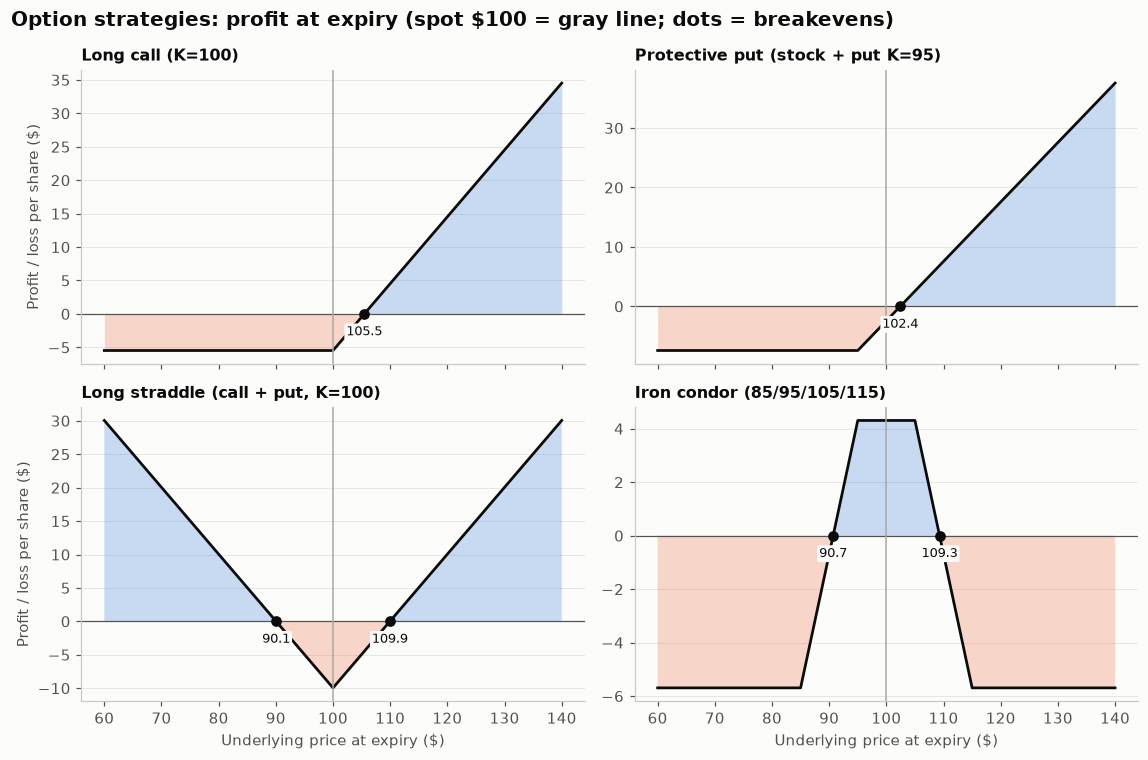

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), sharex=True)
for ax, (name, pnl) in zip(axes.flat, strategies.items()):
    x, y = pnl.index.to_numpy(), pnl.to_numpy()
    ax.fill_between(x, y, 0, where=y >= 0, color=PALETTE[0], alpha=0.25, linewidth=0, interpolate=True)
    ax.fill_between(x, y, 0, where=y < 0, color=PALETTE[1], alpha=0.25, linewidth=0, interpolate=True)
    ax.plot(x, y, color="#0b0b0b", linewidth=1.8)
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.axvline(S0, color="#a9a8a2", linewidth=1)
    cross = np.flatnonzero(np.diff(np.sign(y)) != 0)
    for i in cross:                                   # linear interpolation of breakevens
        be = x[i] - y[i] * (x[i + 1] - x[i]) / (y[i + 1] - y[i])
        ax.scatter(be, 0, s=36, color="#0b0b0b", zorder=3)
        ax.annotate(f"{be:.1f}", (be, 0), xytext=(0, -14), textcoords="offset points",
                    ha="center", fontsize=8.5, color="#0b0b0b",
                    bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none"))
    ax.set_title(name, fontsize=10.5)
    ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.set_xlabel("Underlying price at expiry ($)")
for ax in axes[:, 0]:
    ax.set_ylabel("Profit / loss per share ($)")
fig.suptitle("Option strategies: profit at expiry (spot $100 = gray line; dots = breakevens)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Blue areas are profit and orange areas are loss at expiry. The long call risks only its premium; the protective put caps the downside of owning the stock; the straddle needs a big move either way; the iron condor earns a small, capped profit if the price stays between 95 and 105.

---
Standalone script: [`option_payoff.py`](option_payoff.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)